In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [14]:
from pathlib import Path
from PIL import Image, UnidentifiedImageError

# Ganti dengan nama/path gambar Anda, misalnya: 'foto.png' atau r'C:\Data\foto.jpg'
IMAGE_PATH = '/content/drive/MyDrive/citra digital/JKW.jfif'

image_path = Path(IMAGE_PATH).expanduser()
if not image_path.is_file():raise FileNotFoundError(
        f'File gambar tidak ditemukan: {image_path.resolve()}\n'
        'Periksa IMAGE_PATH dan pastikan file berada di lokasi tersebut.'
    )

try:
    # Salinan terpisah mempertahankan objek asli yang belum dimodifikasi.
    with Image.open(image_path) as opened_image:
        opened_image.load()
        image = opened_image.copy()
        detected_format = opened_image.format
except UnidentifiedImageError as exc:
    raise ValueError(f'Format gambar tidak dikenali atau tidak didukung: {image_path}') from exc
except OSError as exc:
    raise OSError(f'Gambar tidak dapat dibaca: {image_path}. Detail: {exc}') from exc

print(f'Gambar berhasil dibaca: {image_path.resolve()}')

Gambar berhasil dibaca: /content/drive/MyDrive/citra digital/JKW.jfif


In [15]:
width, height = image.size
original_mode = image.mode
original_array = np.asarray(image)
channel_count = len(image.getbands())
pixel_count = width * height

metadata = {
    'Nama file': image_path.name,
    'Ekstensi file': image_path.suffix or '(tanpa ekstensi)',
    'Format terdeteksi Pillow': detected_format or '(tidak diketahui)',
    'Mode warna asli': original_mode,
    'Dimensi (lebar × tinggi)': f'{width} × {height} piksel',
    'Jumlah total piksel': pixel_count,
    'Jumlah kanal/komponen mode': channel_count,
    'Bentuk array asli': str(original_array.shape),
    'Tipe data array': str(original_array.dtype),
    'Nilai minimum array': int(original_array.min()),
    'Nilai maksimum array': int(original_array.max()),
}
print(pd.Series(metadata).to_string())


Nama file                             JKW.jfif
Ekstensi file                            .jfif
Format terdeteksi Pillow                  JPEG
Mode warna asli                            RGB
Dimensi (lebar × tinggi)      552 × 775 piksel
Jumlah total piksel                     427800
Jumlah kanal/komponen mode                   3
Bentuk array asli                (775, 552, 3)
Tipe data array                          uint8
Nilai minimum array                          0
Nilai maksimum array                       255


In [16]:
mode_explanations = {
    'RGB': 'RGB memiliki tiga kanal: Red, Green, dan Blue.',
    'RGBA': 'RGBA memiliki kanal Red, Green, Blue, dan Alpha (transparansi).',
    'L': 'Grayscale L memiliki satu kanal intensitas keabuan.',
    'LA': 'LA memiliki kanal intensitas keabuan dan Alpha.',
    'CMYK': 'CMYK memiliki kanal Cyan, Magenta, Yellow, dan Key/Black.',
    'P': 'P menggunakan indeks warna yang merujuk ke palet; array asli berisi indeks palet.',
    '1': 'Mode 1 menyimpan piksel biner (hitam/putih).',
}
print(f'Mode asli: {original_mode}')
print(mode_explanations.get(original_mode, f'Mode Pillow {original_mode} dengan komponen: {image.getbands()}'))
if original_mode == 'CMYK':
    print('Informasi CMYK asli dipertahankan; sampel array dan kanal akan memakai urutan C, M, Y, K.')
elif original_mode == 'P':
    print('Citra palet akan tetap dianalisis dalam mode P; RGB hanya dipakai pada salinan visualisasi.')


Mode asli: RGB
RGB memiliki tiga kanal: Red, Green, dan Blue.


In [17]:
print(f'array.shape = {original_array.shape}')
if original_array.ndim == 2:
    print('Arti dimensi: (tinggi, lebar) — satu nilai per piksel (grayscale, biner, atau indeks palet).')
elif original_array.ndim == 3:
    print(f'Arti dimensi: (tinggi, lebar, kanal) = ({height}, {width}, {original_array.shape[2]}).')
else:
    print('Array memiliki dimensi tambahan sesuai representasi mode gambar.')

sample = original_array[:min(5, height), :min(5, width)]
print('Sampel matriks kiri atas (maksimal 5 × 5):')
print(sample)

if original_mode in ('RGB', 'RGBA'):
    for channel_index, channel_name in enumerate(image.getbands()):
        print(f'Kanal {channel_name} — sampel 5 × 5:')
        print(original_array[:min(5, height), :min(5, width), channel_index])
elif original_mode == 'CMYK':
    for channel_index, channel_name in enumerate(('Cyan (C)', 'Magenta (M)', 'Yellow (Y)', 'Key/Black (K)')):
        print(f'Kanal {channel_name} — sampel 5 × 5:')
        print(original_array[:min(5, height), :min(5, width), channel_index])

# Koordinat diminta (x=10, y=10), jika ukuran gambar memadai.
x, y = 10, 10
if x < width and y < height:
    print(f'Nilai piksel pada koordinat (x={x}, y={y}): {image.getpixel((x, y))}')
else:
    print(f'Koordinat (x={x}, y={y}) tidak tersedia untuk gambar {width} × {height}; gunakan koordinat lain yang valid.')
print(f'Rentang nilai array yang ditemukan: {original_array.min()} sampai {original_array.max()} (dtype {original_array.dtype}).')


array.shape = (775, 552, 3)
Arti dimensi: (tinggi, lebar, kanal) = (775, 552, 3).
Sampel matriks kiri atas (maksimal 5 × 5):
[[[26 30  3]
  [25 29  2]
  [25 30  0]
  [26 31  1]
  [27 32  2]]

 [[26 30  3]
  [25 29  2]
  [25 30  0]
  [26 31  1]
  [28 33  3]]

 [[27 31  4]
  [26 30  3]
  [26 31  1]
  [27 32  2]
  [28 33  3]]

 [[28 32  5]
  [27 31  4]
  [27 32  2]
  [28 33  3]
  [29 34  4]]

 [[29 33  6]
  [28 32  5]
  [28 33  3]
  [29 34  4]
  [30 35  5]]]
Kanal R — sampel 5 × 5:
[[26 25 25 26 27]
 [26 25 25 26 28]
 [27 26 26 27 28]
 [28 27 27 28 29]
 [29 28 28 29 30]]
Kanal G — sampel 5 × 5:
[[30 29 30 31 32]
 [30 29 30 31 33]
 [31 30 31 32 33]
 [32 31 32 33 34]
 [33 32 33 34 35]]
Kanal B — sampel 5 × 5:
[[3 2 0 1 2]
 [3 2 0 1 3]
 [4 3 1 2 3]
 [5 4 2 3 4]
 [6 5 3 4 5]]
Nilai piksel pada koordinat (x=10, y=10): (33, 39, 3)
Rentang nilai array yang ditemukan: 0 sampai 255 (dtype uint8).


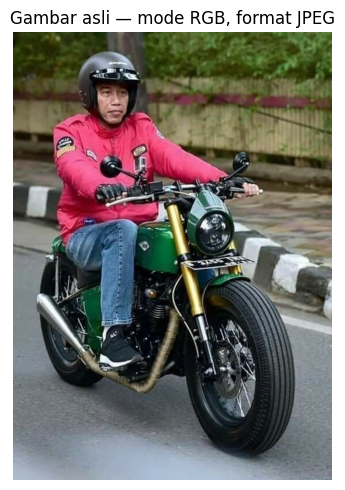

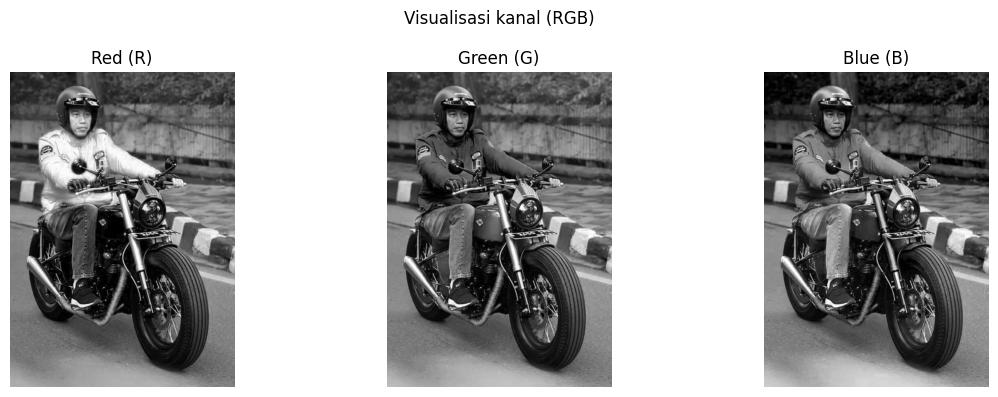

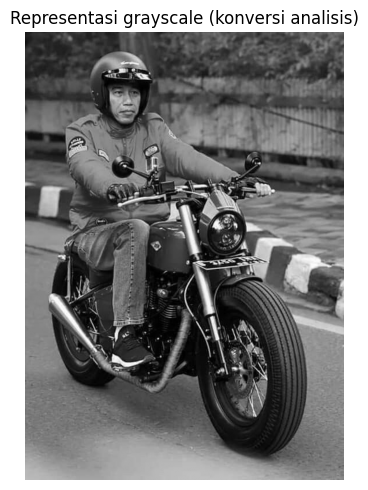

In [18]:
fig, ax = plt.subplots(figsize=(6, 5))
if original_mode == 'CMYK':
    display_image = image.convert('RGB')
elif original_mode == 'P':
    display_image = image.convert('RGBA' if 'transparency' in image.info else 'RGB')
else:
    display_image = image
ax.imshow(display_image, cmap='gray' if display_image.mode in ('1', 'L') else None)
ax.set_title(f'Gambar asli — mode {original_mode}, format {detected_format}')
ax.axis('off')
plt.tight_layout()
plt.show()

if original_mode in ('RGB', 'RGBA'):
    channel_source = image
elif original_mode == 'CMYK':
    channel_source = image
else:
    channel_source = image.convert('RGBA' if 'transparency' in image.info else 'RGB')

channel_names = channel_source.getbands()
channel_arrays = np.asarray(channel_source)
channel_titles = {'R': 'Red (R)', 'G': 'Green (G)', 'B': 'Blue (B)', 'A': 'Alpha (A)',
                  'C': 'Cyan (C)', 'M': 'Magenta (M)', 'Y': 'Yellow (Y)', 'K': 'Key/Black (K)'}
fig, axes = plt.subplots(1, len(channel_names), figsize=(4 * len(channel_names), 4), squeeze=False)
for index, channel_name in enumerate(channel_names):
    axes[0, index].imshow(channel_arrays[:, :, index], cmap='gray', vmin=0, vmax=255)
    axes[0, index].set_title(channel_titles.get(channel_name, f'Kanal {channel_name}'))
    axes[0, index].axis('off')
fig.suptitle(f'Visualisasi kanal ({channel_source.mode})')
plt.tight_layout()
plt.show()

gray_image = image.convert('L')
plt.figure(figsize=(6, 5))
plt.imshow(gray_image, cmap='gray', vmin=0, vmax=255)
plt.title('Representasi grayscale (konversi analisis)')
plt.axis('off')
plt.tight_layout()
plt.show()


In [19]:
# Pilih beberapa koordinat valid dan unik, dalam urutan (x, y).
coordinates = [(0, 0), (width - 1, 0), (0, height - 1), (width - 1, height - 1),
               (width // 2, height // 2)]
if width > 10 and height > 10:
    coordinates.append((10, 10))
coordinates = list(dict.fromkeys(coordinates))

pixel_checks = []
for px, py in coordinates:
    pillow_value = image.getpixel((px, py))
    numpy_value = original_array[py, px]
    equal = np.array_equal(np.asarray(pillow_value), np.asarray(numpy_value))
    pixel_checks.append({
        'Koordinat (x, y)': (px, py),
        'Nilai Pillow': pillow_value,
        'Nilai NumPy': numpy_value.tolist() if isinstance(numpy_value, np.ndarray) else numpy_value.item() if isinstance(numpy_value, np.generic) else numpy_value,
        'Sesuai': bool(equal),
    })

checks_df = pd.DataFrame(pixel_checks)
display(checks_df)
all_pixels_equal = np.array_equal(np.asarray(image), original_array)
print(f'Verifikasi seluruh data piksel (mode {image.mode} pada keduanya): {"VALID" if all_pixels_equal else "TIDAK VALID"}')


,"Koordinat (x, y)",Nilai Pillow,Nilai NumPy,Sesuai
0,"(0, 0)","(26, 30, 3)","[26, 30, 3]",True
1,"(551, 0)","(79, 119, 48)","[79, 119, 48]",True
2,"(0, 774)","(176, 192, 208)","[176, 192, 208]",True
3,"(551, 774)","(122, 132, 141)","[122, 132, 141]",True
4,"(276, 387)","(2, 91, 43)","[2, 91, 43]",True
5,"(10, 10)","(33, 39, 3)","[33, 39, 3]",True


Verifikasi seluruh data piksel (mode RGB pada keduanya): VALID


In [20]:
summary = pd.DataFrame([
    {'Aspek': 'Format gambar', 'Hasil': detected_format or '(tidak diketahui)'},
    {'Aspek': 'Mode warna asli', 'Hasil': original_mode},
    {'Aspek': 'Dimensi gambar', 'Hasil': f'{width} × {height} piksel'},
    {'Aspek': 'Total piksel', 'Hasil': pixel_count},
    {'Aspek': 'Bentuk array asli', 'Hasil': str(original_array.shape)},
    {'Aspek': 'Jumlah kanal/komponen mode', 'Hasil': channel_count},
    {'Aspek': 'Tipe data', 'Hasil': str(original_array.dtype)},
    {'Aspek': 'Nilai minimum piksel', 'Hasil': int(original_array.min())},
    {'Aspek': 'Nilai maksimum piksel', 'Hasil': int(original_array.max())},
])
display(summary)


,Aspek,Hasil
0,Format gambar,JPEG
1,Mode warna asli,RGB
2,Dimensi gambar,552 × 775 piksel
3,Total piksel,427800
4,Bentuk array asli,"(775, 552, 3)"
5,Jumlah kanal/komponen mode,3
6,Tipe data,uint8
7,Nilai minimum piksel,0
8,Nilai maksimum piksel,255


In [21]:
print(f'File {image_path.name} terdeteksi sebagai {detected_format} dengan mode asli {original_mode}.')
print(f'Ukuran citra adalah lebar {width} piksel × tinggi {height} piksel, sehingga berisi {pixel_count:,} piksel.')
print(f'Array NumPy memiliki bentuk {original_array.shape}, tipe data {original_array.dtype}, dan rentang nilai {original_array.min()}–{original_array.max()}.')
if original_mode == 'P':
    print('Mode P berarti nilai pada array asli adalah indeks palet, bukan nilai RGB langsung.')
elif original_mode == 'CMYK':
    print('Array asli mempertahankan empat kanal CMYK; tidak dibandingkan dengan hasil konversi RGB.')
print(f'Pemeriksaan seluruh array terhadap data Pillow: {"VALID" if all_pixels_equal else "TIDAK VALID"}.')


File JKW.jfif terdeteksi sebagai JPEG dengan mode asli RGB.
Ukuran citra adalah lebar 552 piksel × tinggi 775 piksel, sehingga berisi 427,800 piksel.
Array NumPy memiliki bentuk (775, 552, 3), tipe data uint8, dan rentang nilai 0–255.
Pemeriksaan seluruh array terhadap data Pillow: VALID.
